# Classification

## Setup & Loading Data

In [39]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC


In [2]:
proj_root = Path.cwd()
if proj_root.name == "src":
    proj_root = proj_root.parent
data_dir = proj_root / "data"

In [3]:
classification_train = pd.read_csv(data_dir/"Classification_train.csv")
classification_val = pd.read_csv(data_dir / "classification_val.csv")
classification_test = pd.read_csv(data_dir / "classification_test.csv")

print(f"Train shape: {classification_train.shape}")
print(f"Val shape: {classification_val.shape}")
print(f"Test shape: {classification_test.shape}")

Train shape: (87500, 28)
Val shape: (12500, 28)
Test shape: (50000, 27)


In [4]:
print(f"Train months: {classification_train["Month"].unique()}")
print(f"Val months: {classification_val['Month'].unique()}")
print(f"Test months: {classification_test['Month'].unique()}")

Train months: <StringArray>
['January', 'February', 'March', 'April', 'May', 'June', 'July']
Length: 7, dtype: str
Val months: <StringArray>
['August']
Length: 1, dtype: str
Test months: <StringArray>
['September', 'October', 'November', 'December']
Length: 4, dtype: str


Validation was already split from train in 'EDA.ipynb'. Because the train set contained the first 8 months of the year and test contained the final 4, I decided to split the final month off from the training set to use as validation.

In [5]:
print(classification_train.columns.tolist())
print(classification_val.columns.tolist())
print(classification_test.columns.tolist())

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']
['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance'

In [6]:
# Splitting
y_train = classification_train["Credit_Score"]
x_train = classification_train.drop(columns=["Credit_Score"])
y_val = classification_val["Credit_Score"]
x_val = classification_val.drop(columns=["Credit_Score"])
x_test = classification_test # No need to split, no target

print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_val shape: {x_val.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"x_test shape: {x_test.shape}")

x_train shape: (87500, 27)
y_train shape: (87500,)
x_val shape: (12500, 27)
y_val shape: (12500,)
x_test shape: (50000, 27)


### Preparing Features

In [7]:
# Removing IDs
id_columns = ["ID", "Customer_ID", "Name", "SSN"]

print("Columns before removal:")
print(f"x_train: {x_train.columns.tolist()}")
print(f"x_val: {x_val.columns.tolist()}")
print(f"x_test: {x_test.columns.tolist()}")

x_train = x_train.drop(columns=id_columns)
x_val = x_val.drop(columns=id_columns)
x_test = x_test.drop(columns=id_columns)
    
print("\nColumns after removal:")
print(f"x_train: {x_train.columns.tolist()}")
print(f"x_val: {x_val.columns.tolist()}")
print(f"x_test: {x_test.columns.tolist()}")

Columns before removal:
x_train: ['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']
x_val: ['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behav

In [8]:
# Removing month as well, val and test come from months not
# in training data. Avoids learning month specific patters that
# may not work help with later months.

print("Columns before removal:")
print(f"x_train: {x_train.columns.tolist()}")
print(f"x_val: {x_val.columns.tolist()}")
print(f"x_test: {x_test.columns.tolist()}")

x_train = x_train.drop(columns=["Month"])
x_val = x_val.drop(columns=["Month"])
x_test = x_test.drop(columns=["Month"])

print("\nColumns after removal:")
print(f"x_train: {x_train.columns.tolist()}")
print(f"x_val: {x_val.columns.tolist()}")
print(f"x_test: {x_test.columns.tolist()}")

Columns before removal:
x_train: ['Month', 'Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']
x_val: ['Month', 'Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']
x_test: ['Month', 'Age', 'Occupation', 'Annual

### Encoding

Before doing a blanket dummies one hot encoding, 'Type_of_Loan' needs to be handled as there are thousands of different unique strings. The string seems to represent the types of loans present for the person. To handle these  I'll split the string by commas and one hot encode for each of the types split off.

In [9]:
x_train["Type_of_Loan"].head()

0    Auto Loan, Credit-Builder Loan, Personal Loan,...
1    Auto Loan, Credit-Builder Loan, Personal Loan,...
2    Auto Loan, Credit-Builder Loan, Personal Loan,...
3    Auto Loan, Credit-Builder Loan, Personal Loan,...
4    Auto Loan, Credit-Builder Loan, Personal Loan,...
Name: Type_of_Loan, dtype: str

In [10]:
# Break into pieces then One hot encode the loan type strings

def encode_loans(values):
    return (
        values.str.replace("and ", "", regex=False)  # Get rid of ands
        .str.replace(r"\s*,\s*", "|", regex=True)  # Replace commas with '|'
        .str.get_dummies(sep="|")  # Dummies separated on '|'
        .add_prefix("Loan_")
    )
    
train_loans = encode_loans(x_train["Type_of_Loan"])
# Matching val and test to train cols
val_loans = encode_loans(x_val["Type_of_Loan"]).reindex(
    columns=train_loans.columns, fill_value=0
)
test_loans = encode_loans(x_test["Type_of_Loan"]).reindex(
    columns=train_loans.columns, fill_value=0
)

# Replace old strings with new encoded
x_train = x_train.drop(columns=["Type_of_Loan"]).join(train_loans)
x_val = x_val.drop(columns=["Type_of_Loan"]).join(val_loans)
x_test = x_test.drop(columns=["Type_of_Loan"]).join(test_loans)

print("Turned into:")
print(train_loans.columns.tolist())

Turned into:
['Loan_Auto Loan', 'Loan_Credit-Builder Loan', 'Loan_Debt Consolidation Loan', 'Loan_Home Equity Loan', 'Loan_Mortgage Loan', 'Loan_No loans', 'Loan_Not Specified', 'Loan_Payday Loan', 'Loan_Personal Loan', 'Loan_Student Loan', 'Loan_Unknown']


In [11]:
# One hot encoding the othyer categorical columns
categorical_columns = x_train.select_dtypes(include=[
    "object", "string", "category"
]).columns

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Learn from train, apply to others
train_encoded = encoder.fit_transform(x_train[categorical_columns])
val_encoded = encoder.transform(x_val[categorical_columns])
test_encoded = encoder.transform(x_test[categorical_columns])

# Replace
encoded_columns = encoder.get_feature_names_out(categorical_columns)
x_train = x_train.drop(columns=categorical_columns).join(
    pd.DataFrame(train_encoded, columns=encoded_columns, index=x_train.index)
)
x_val = x_val.drop(columns=categorical_columns).join(
    pd.DataFrame(val_encoded, columns=encoded_columns, index=x_val.index)
)
x_test = x_test.drop(columns=categorical_columns).join(
    pd.DataFrame(test_encoded, columns=encoded_columns, index=x_test.index)
)

# make sure all are numeric and match
for name, data in [("Training", x_train), ("Validation", x_val), ("Test", x_test)]:
    print(name, data.shape)
    non_numeric_cols = data.select_dtypes(exclude="number").columns.tolist()
    if non_numeric_cols:
        print(f"Found numeric cols: {non_numeric_cols}")
    else:
        print(f"No non numeric cols left in {name}")

Training (87500, 58)
No non numeric cols left in Training
Validation (12500, 58)
No non numeric cols left in Validation
Test (50000, 58)
No non numeric cols left in Test


In [12]:
# Scaling for logi reg and svm, other model used will be rand forest, no scaling needed
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

## Training

In [13]:
def val_results(model, x, y, name):
    predictions = model.predict(x)
    print(f"Validation accuracy: {accuracy_score(y, predictions)}")
    print(classification_report(y, predictions, zero_division=0))
    
    ConfusionMatrixDisplay.from_predictions(
        y,
        predictions,
        labels=["Good", "Standard", "Poor"],
        cmap="Blues",
        values_format="d",
    )
    plt.title(f"{name}")
    plt.tight_layout()
    plt.show()

### Logistic Regression

In [14]:
logistic_model = LogisticRegression(max_iter=2000, random_state=24)
logistic_model.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",24
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

Validation accuracy: 0.57632
              precision    recall  f1-score   support

        Good       0.48      0.51      0.49      2413
        Poor       0.58      0.42      0.49      3602
    Standard       0.61      0.69      0.65      6485

    accuracy                           0.58     12500
   macro avg       0.56      0.54      0.54     12500
weighted avg       0.58      0.58      0.57     12500



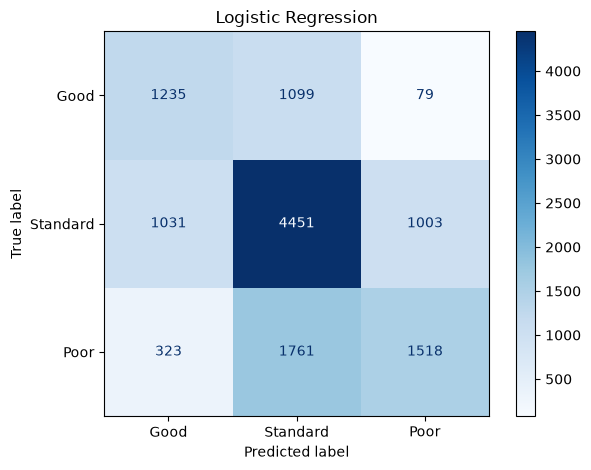

In [15]:
val_results(logistic_model, x_val_scaled, y_val, "Logistic Regression")

Logistic regression only achieved 57.63% accuracy.

It performed best on standard scores but only identified 42% of poor records. Its macro F1 of 0.54 shows quite poor performance across the three classes.

The confusion matrix shows that many of the good and poor records are predicted as standard. 1,761 poor records were labelled standard compared with 1,518 correctly labelled as poor.

I will test class weight balancing to see wether recognizing good and poor improves.

In [16]:
# Testing balanced class weights
balanced_logistic = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=24
)
balanced_logistic.fit(x_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",24
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

Validation accuracy: 0.56664
              precision    recall  f1-score   support

        Good       0.43      0.71      0.54      2413
        Poor       0.55      0.59      0.57      3602
    Standard       0.69      0.50      0.58      6485

    accuracy                           0.57     12500
   macro avg       0.56      0.60      0.56     12500
weighted avg       0.60      0.57      0.57     12500



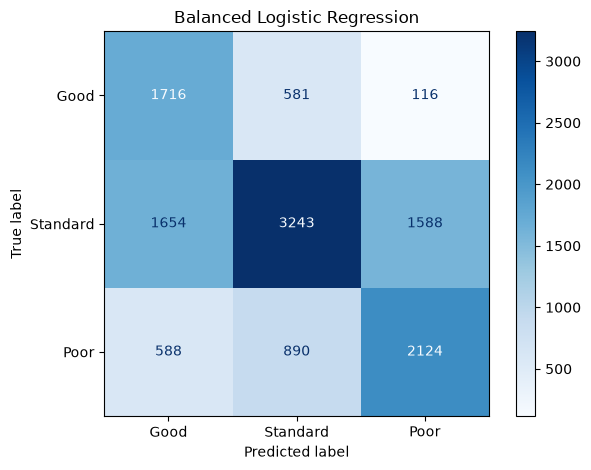

In [17]:
val_results(balanced_logistic, x_val_scaled, y_val, "Balanced Logistic Regression")

Balanced class weights increased macro F1 from 0.54 to 0.56.  
Poor recall improved from 42% to 59% and good recall from 51% to 71%.  
Standard recall fell from 69% to 50%.

Accuracy dropped from 57.63% to 56.66%. The model seems to catch more good and poor records, but incorrectly assigns those labels to more standard records.

I will keep the balanced logistic regression for the later model comparison, prioritising the increase in macro F1 and recognition of poor and good scores over one point in accuracy.

### Random Forest

In [23]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced", # Going balanced again
    random_state=24,
    n_jobs=1
)
forest_model.fit(x_train, y_train) # Fit on unscaled data

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",24
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

Validation accuracy: 0.7248
              precision    recall  f1-score   support

        Good       0.64      0.73      0.68      2413
        Poor       0.71      0.80      0.75      3602
    Standard       0.78      0.68      0.73      6485

    accuracy                           0.72     12500
   macro avg       0.71      0.74      0.72     12500
weighted avg       0.73      0.72      0.72     12500



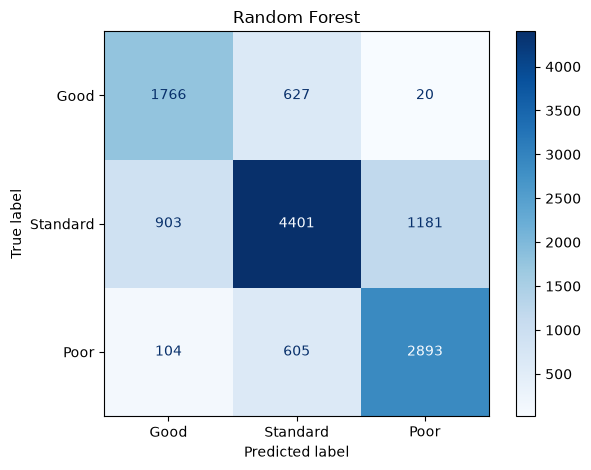

In [ ]:
val_results(forest_model, x_val, y_val, "Random Forest")

Random forest achieved 72.48% validation accuracy and a macro F1 of 0.72, improving on both logistic regression models.

It correctly identified 80% of poor records, compared with 59% for balanced logistic regression. Good recall was 73% and standard was 68%.

The largest mistake from this model was predicting poor for 1,181 actually standard records. Random forest outperforms the logistic models making it the best so far. SVM is next.

In [24]:
# Trying RF with min_samples_leaf=5
leaf_5_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",  # Going balanced again
    random_state=24,
    n_jobs=1,
    min_samples_leaf=5
)
leaf_5_forest_model.fit(x_train, y_train)  # Fit on unscaled data

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",24
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

Validation accuracy: 0.67616
              precision    recall  f1-score   support

        Good       0.52      0.73      0.61      2413
        Poor       0.69      0.76      0.72      3602
    Standard       0.77      0.61      0.68      6485

    accuracy                           0.68     12500
   macro avg       0.66      0.70      0.67     12500
weighted avg       0.70      0.68      0.68     12500



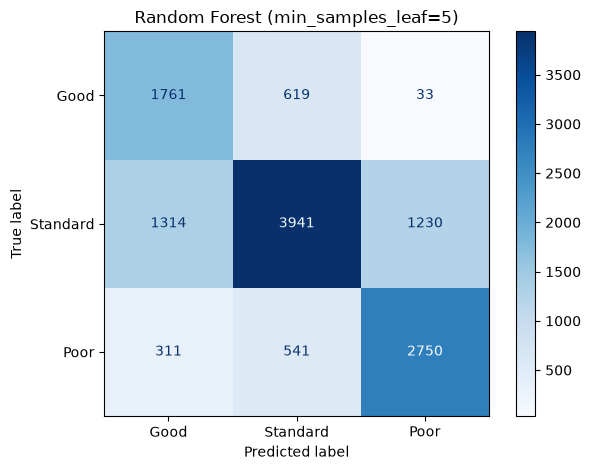

In [27]:
val_results(leaf_5_forest_model, x_val, y_val, "Random Forest (min_samples_leaf=5)")

Increasing min_samples_leaf to 5 reduced the val accuracy from 72.48% down to 67.62% and macro F1 from 0.72 to 0.67. Poor recall also fell.

This change made validation performance worse so I will stick with the first RF model.

### SVM

In [20]:
svm_model = SVC(kernel="rbf", C=1, gamma="scale")
svm_model.fit(x_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Validation accuracy: 0.61888
              precision    recall  f1-score   support

        Good       0.48      0.57      0.52      2413
        Poor       0.66      0.56      0.60      3602
    Standard       0.66      0.67      0.67      6485

    accuracy                           0.62     12500
   macro avg       0.60      0.60      0.60     12500
weighted avg       0.63      0.62      0.62     12500



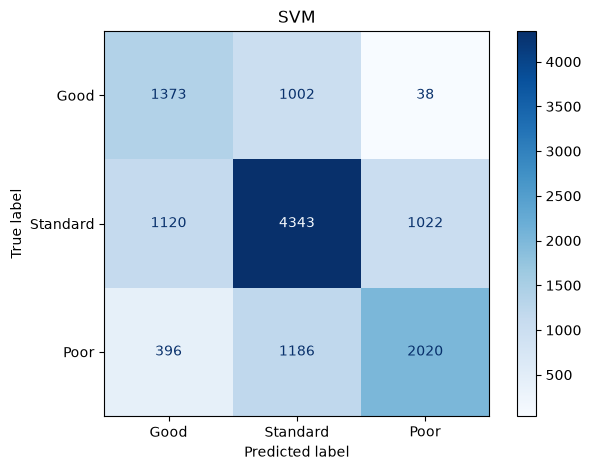

In [21]:
val_results(svm_model, x_val_scaled, y_val, "SVM")

RBF SVM achieved a 61.89% validation accuracy and a macro F1 of 0.60.  
While being better than both logistic models, it is below RF's 72.48% accuracy and 0.72 macro F1.

It identified 56% of poor records, compared to 80% for random forest. Many poor and good records were still predicted as standard.

Random forest remains the strongest model.

In [26]:
# Trying balancing
balanced_svm_model = SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced")
balanced_svm_model.fit(x_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Validation accuracy: 0.58392
              precision    recall  f1-score   support

        Good       0.43      0.72      0.54      2413
        Poor       0.58      0.68      0.63      3602
    Standard       0.74      0.48      0.58      6485

    accuracy                           0.58     12500
   macro avg       0.58      0.63      0.58     12500
weighted avg       0.63      0.58      0.59     12500



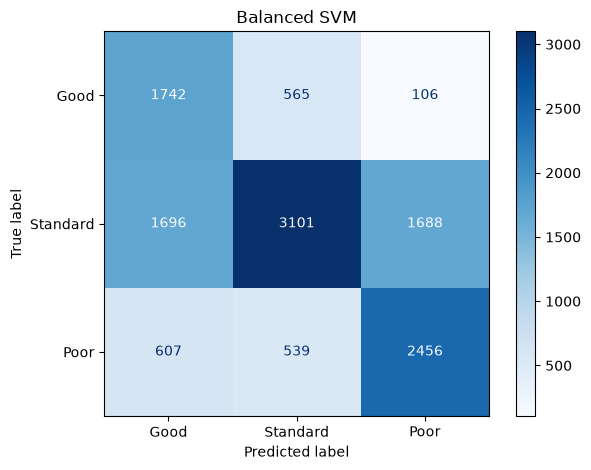

In [29]:
val_results(balanced_svm_model, x_val_scaled, y_val, "Balanced SVM")

Balanced class weights increased poor recall from 56% to 68% and good recall from 57% to 72%. However, standard recall fell from 67% to 48%.

Accuracy dropped from 61.89% to 58.38%, and macro F1 fell from 0.60 to 0.58. 

I will keep the balanced SVM because it identifies more good and poor records, which i feel is more important for risk classification. This comes at the cost of lower accuracy and macro F1, with more standard records incorrectly labelled good or poor.

## Comparison

In [ ]:
# Best versions of the 3 models
selected_models = {
    "Balanced Logistic Regression" : (balanced_logistic, x_val_scaled),
    "Random Forest": (forest_model, x_val),
    "Balanced RBF SVM": (balanced_svm_model, x_val_scaled)
}

# Building metrics table
results = []
for name, (model, features) in selected_models.items():
    predictions = model.predict(features)
    report = classification_report(y_val, predictions, output_dict=True, zero_division=0)
    
    results.append(
        {
            "Model": name,
            "Accuracy": report["accuracy"],
            "Macro precision": report["macro avg"]["precision"],
            "Macro recall": report["macro avg"]["recall"],
            "Macro F1": report["macro avg"]["f1-score"],
            # Logging poor info as they are the risky ones
            "Poor precision": report["Poor"]["precision"],
            "Poor recall": report["Poor"]["recall"]
        }
    )
    
comparison_table = pd.DataFrame(results).set_index("Model")
display(comparison_table.round(2))

,Accuracy,Macro precision,Macro recall,Macro F1,Poor precision,Poor recall
Model,,,,,,
Balanced Logistic Regression,0.57,0.56,0.60,0.56,0.55,0.59
Random Forest,0.72,0.71,0.74,0.72,0.71,0.80
Balanced RBF SVM,0.58,0.58,0.63,0.58,0.58,0.68


Random forest performed best across all comparison metrics, with 72.48% and a macro F1 of 0.72.

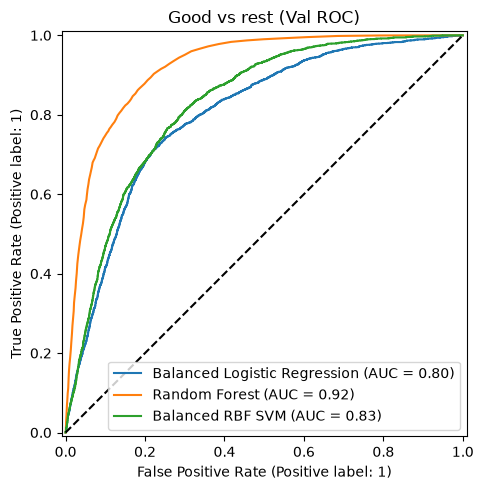

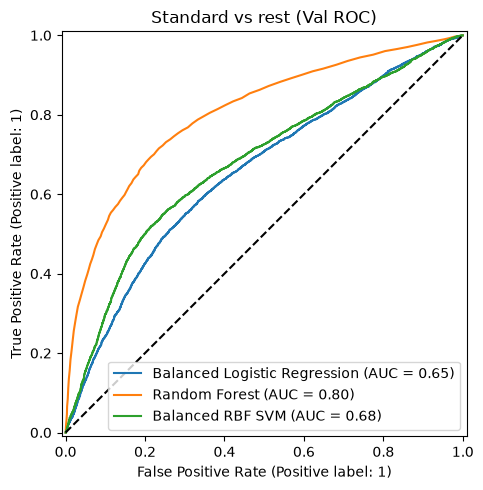

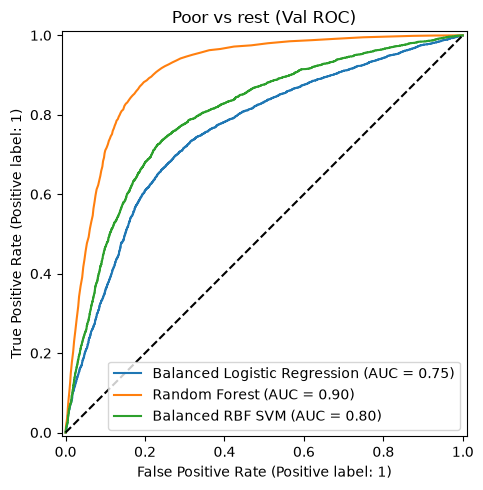

In [33]:
# Curve plots
credit_classes = ["Good", "Standard", "Poor"]

for credit_class in credit_classes:
    fig, ax = plt.subplots(figsize=(7,5))

    for name, (model, features) in selected_models.items():
        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(features)
        else:
            scores = model.decision_function(features)
            
        column = list(model.classes_).index(credit_class)
        
        # Calc and plot ROC, with AUC in the legend
        RocCurveDisplay.from_predictions(
            y_val == credit_class,
            scores[:, column],
            name=name,
            ax=ax
        )
        
    ax.plot([0,1], [0,1], "k--")
    ax.set_title(f"{credit_class} vs rest (Val ROC)")
    plt.tight_layout()
    plt.show()
    

Random forest has the highest AUC for good (0.92), standard (0.80) and poor (0.90). Its curves are the largest showing better separation of each category from the others.

The standard class has the lowest AUC for every model, meaning it is the hardest category to distinguish by these scores.

Together with its stronger macro F1 and poor recall, random forest will be selected as the final model.

## Test Prediction of Best Model

In [34]:
test_predictions = forest_model.predict(x_test)

# Creating a new copy of the test set so notebook can be reran from start
# Brief wants me to append the predictions to the test set
test_results = classification_test.copy()
test_results["Predicted_Credit_Score"] = test_predictions
output_path = data_dir/"classification_test_predictions.csv"
test_results.to_csv(output_path, index=False)

In [36]:
test_results.head(25)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Predicted_Credit_Score
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,35.030402,273.0,No,49.574949,236.642682,Low_spent_Small_value_payments,186.266702,Good
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,33.053114,274.0,No,49.574949,21.465380,High_spent_Medium_value_payments,361.444004,Good
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,33.811894,219.0,No,49.574949,148.233938,Low_spent_Medium_value_payments,264.675446,Good
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24.0,821-00-0265,Scientist,19114.12,3095.905000,3.0,...,Good,809.98,32.430559,276.0,No,49.574949,39.082511,High_spent_Medium_value_payments,343.826873,Good
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28.0,004-07-5839,Unknown,34847.84,3037.986667,2.0,...,Good,605.03,25.926822,327.0,No,18.816215,39.684018,High_spent_Large_value_payments,485.298434,Good
5,0x1617,CUS_0x21b1,October,Rick Rothackerj,28.0,#F%$D@*&8,Teacher,34847.84,3037.986667,2.0,...,Good,605.03,30.116600,328.0,No,18.816215,251.627369,Low_spent_Large_value_payments,303.355083,Good
6,0x1618,CUS_0x21b1,November,Rick Rothackerj,28.0,004-07-5839,Teacher,34847.84,3037.986667,2.0,...,Unknown,605.03,30.996424,329.0,No,18.816215,72.680145,High_spent_Large_value_payments,452.302307,Good
7,0x1619,CUS_0x21b1,December,Rick Rothackerj,28.0,004-07-5839,Teacher,34847.84,3037.986667,2.0,...,Unknown,605.03,33.875167,330.0,No,18.816215,153.534488,Unknown,421.447964,Good
8,0x1622,CUS_0x2dbc,September,Langep,35.0,486-85-3974,Engineer,143162.64,3095.905000,1.0,...,Good,1303.01,35.229707,221.0,No,246.992319,397.503654,Low_spent_Medium_value_payments,854.226027,Good
9,0x1623,CUS_0x2dbc,October,Langep,35.0,486-85-3974,Engineer,143162.64,12187.220000,1.0,...,Good,1303.01,35.685836,222.0,No,246.992319,453.615131,Low_spent_Large_value_payments,788.114550,Good


## Model Interpretation

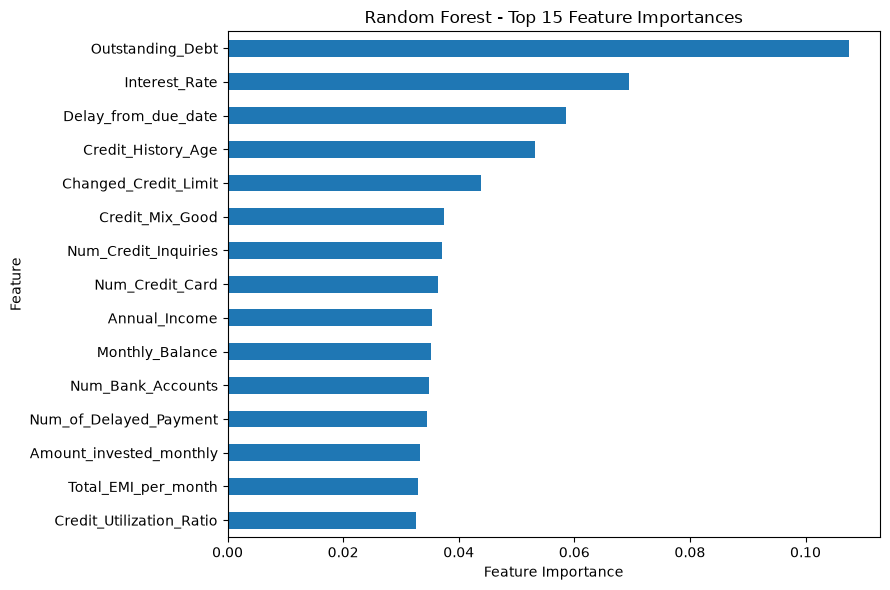

In [37]:
# Feature importance of the RF model
importance = pd.Series(
    forest_model.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False)

# Plotting top 15 features
importance.head(15).sort_values().plot.barh(figsize=(9,6))
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Outstanding debt has the highest feature importance, followed by interest rate, payment delays and credit history age.

Debt and payment delays also showed clear differences between the clusters from clustering, so there is some overlap between the features describing the customer groupings and those used to predict credit scores. Makes sense.

Income is lower down in the rankings, suggesting that this model relies more on debt and repayment history.

### Quick Final Test

I want to test if using only the most important features from the previous RF model will result in a more precise model.

Features kept: ['Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date', 'Credit_History_Age', 'Changed_Credit_Limit']
Validation accuracy: 0.74592
              precision    recall  f1-score   support

        Good       0.66      0.76      0.70      2413
        Poor       0.73      0.81      0.77      3602
    Standard       0.80      0.71      0.75      6485

    accuracy                           0.75     12500
   macro avg       0.73      0.76      0.74     12500
weighted avg       0.75      0.75      0.75     12500



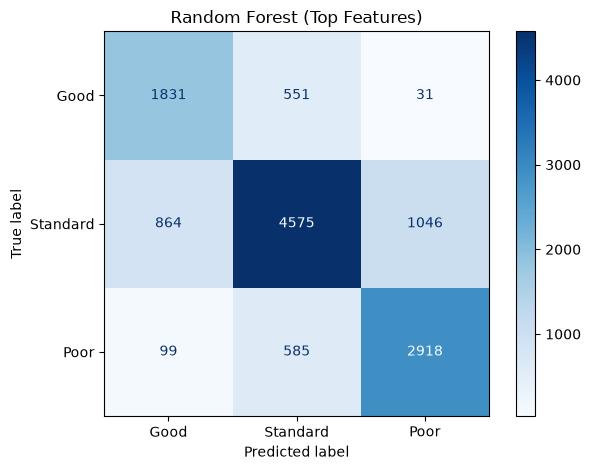

In [41]:
n_features = 5
top_feats = importance.head(n_features).index.tolist()
print(f"Features kept: {top_feats}")

top_feat_forest = clone(forest_model)
top_feat_forest.fit(x_train[top_feats], y_train)

val_results(top_feat_forest, x_val[top_feats], y_val, "Random Forest (Top Features)")

Surprisingly, it seems that using only the five highest ranked features actually improved validation accuracy from 72.48% to 74.59% and macro F1 from 0.72 to 0.74. F1 improved for all three credit classes.